# An agricultural researcher claims that the average crop yield of a particular region is 40 tons per hectare.

# You collect data from 10 farms to check whether the actual average crop yield is different from 40 tons. 


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t,ttest_1samp

In [16]:
crop_yield = [38, 42, 39, 41, 37, 43, 40, 36, 44, 39]
df = pd.DataFrame({"Crop_Yield" : crop_yield})
df

,Crop_Yield
0,38
1,42
2,39
3,41
4,37
5,43
6,40
7,36
8,44
9,39


In [17]:
population_mean = 40
sample_mean = df["Crop_Yield"].mean()
sample_size = len(df)
DOF = sample_size - 1
alpha = 0.05
print("Population mean : ",population_mean)
print("Sample mean : ",sample_mean)
print("significance level : ",alpha)
print("Degree of freedom : ",DOF)
print("Sample size : ",sample_size)

Population mean :  40
Sample mean :  39.9
significance level :  0.05
Degree of freedom :  9
Sample size :  10


In [18]:
t_stats,p_value = ttest_1samp(df["Crop_Yield"],population_mean)
print("t test : ",t_stats)
print("p_value : ",p_value)  

t test :  -0.12156613477096789
p_value :  0.9059136241299459


In [19]:
critical_value = t.ppf(1-alpha/2,DOF)
lower_Fence = -critical_value
upper_Fence = critical_value
print("Critical value  : ",critical_value)
print("lower fence : ",lower_Fence)
print("upper fence : ",upper_Fence)


Critical value  :  2.262157162798205
lower fence :  -2.262157162798205
upper fence :  2.262157162798205


In [20]:
if p_value < alpha :
    print("Decision : we reject the null hypothesis .")
    print("Conclusion : there are sufficent evidence at 5 % significance level that the average crop yield is different .")
else :
    print("Decision : we are fail to reject the null hypothesis . ")
    print("there are not sufficeint evidence at 5 % perecent significane level that the average crop yield is different . ")

Decision : we are fail to reject the null hypothesis . 
there are not sufficeint evidence at 5 % perecent significane level that the average crop yield is different . 


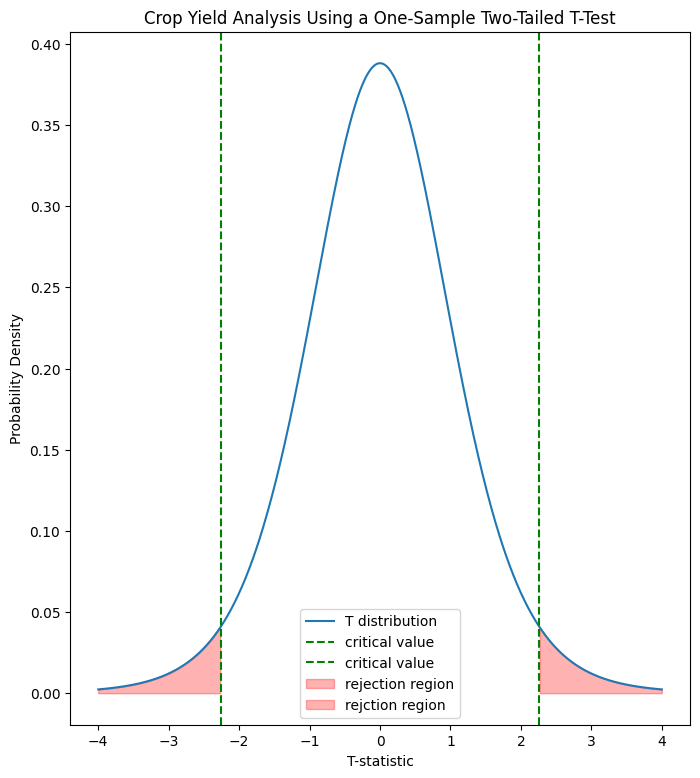

In [51]:
x = np.linspace(-4,4,800)
y = t.pdf(x,DOF)
plt.figure(figsize = (8,9))
plt.plot(x,y,label = "T distribution")

plt.axvline(critical_value,color = "green",linestyle = "--",label = "critical value")
plt.axvline(-critical_value,color = "green",linestyle = "--",label = "critical value")
plt.fill_between(x,y,where = (x <= -critical_value),alpha = 0.3,label = "rejection region",color = "red")
plt.fill_between(x,y,where = (x >= critical_value),alpha = 0.3,color = "red",label = "rejction region")
plt.title("Crop Yield Analysis Using a One-Sample Two-Tailed T-Test")
plt.xlabel("T-statistic")
plt.ylabel("Probability Density")
plt.legend()
plt.show()

